In [8]:
from pathlib import Path
import cv2

grid_dir = Path(r"C:\Users\alagi\shape-sensing\grid_data")
files = sorted(grid_dir.glob("*.png"))

print(f"Found {len(files)} images in {grid_dir}")
images = []
for f in files:
    img = cv2.imread(str(f))
    if img is None:
        print(f"Skipping unreadable image: {f.name}")
        continue
    images.append((f.name, img))

if images:
    print("Example file:", images[0][0])
    print("Example shape:", images[0][1].shape)
else:
    print("No PNG images were found in the grid directory.")


Found 3 images in C:\Users\alagi\shape-sensing\grid_data
Example file: img_r00_c00.png
Example shape: (720, 1280, 3)


img_r00_c00.png: length 366 px, fit error rms 0.16 px, max 0.68 px
  control points [px]: [[626.3, 200.2], [629.4, 240.7], [634.5, 321.9], [647.3, 443.3], [649.2, 524.8], [651.1, 565.4]]
img_r01_c00.png: length 342 px, fit error rms 0.27 px, max 1.39 px
  control points [px]: [[618.5, 199.8], [613.3, 237.4], [594.6, 311.6], [549.2, 416.3], [509.0, 481.3], [486.5, 511.6]]
img_r02_c00.png: length 335 px, fit error rms 0.20 px, max 0.73 px
  control points [px]: [[610.9, 200.0], [598.7, 235.4], [560.4, 300.2], [476.2, 375.9], [407.5, 406.3], [372.6, 419.2]]


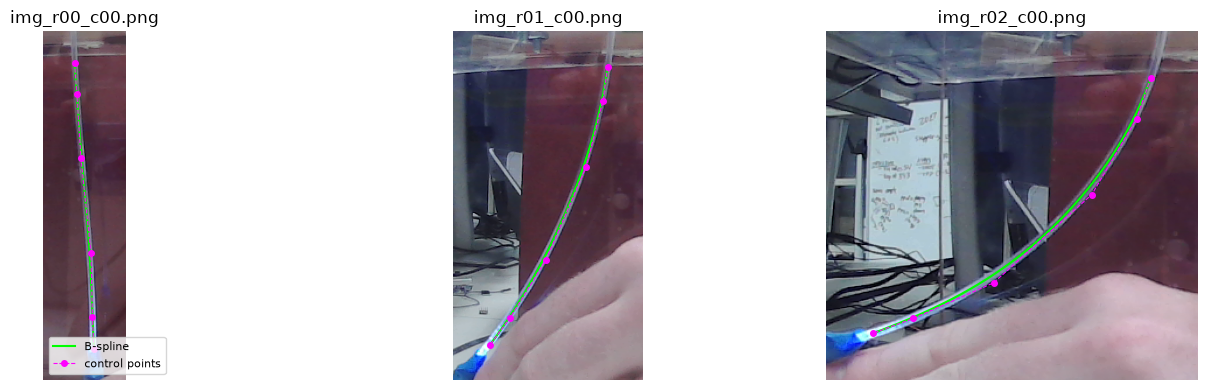

In [9]:
# curve representation of the fiber: cubic B-spline with N_CTRL control points over normalised arc length u in [0, 1]
# (u = 0 at the clamp, u = 1 at the tip). Every image gets the same number of parameters: a (N_CTRL, 2) array in px.
import sys, json, importlib
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import make_lsq_spline

sys.path.insert(0, r"C:\Users\alagi\shape-sensing\sw")
import segment_fiber as sf
importlib.reload(sf)   # pick up edits to segment_fiber.py without restarting the kernel

N_CTRL = 6   # control points per curve (>= 4 for a cubic)
DEG = 3

cfg = json.loads((grid_dir / "seg_config.json").read_text())   # clamp point, clicked once per folder
inner = np.linspace(0, 1, N_CTRL - DEG + 1)[1:-1]
knots = np.r_[[0] * (DEG + 1), inner, [1] * (DEG + 1)]          # clamped uniform knots

curves = {}
fig, axes = plt.subplots(1, len(images), figsize=(5 * len(images), 4), squeeze=False)
for ax, (name, img) in zip(axes[0], images):
    try:
        cl = sf.segment(img, cfg["clamp"], cfg.get("init_dir", sf.INIT_DIR))["centerline"]
    except RuntimeError as e:
        print(f"{name}: segmentation failed ({e})")
        continue
    u, xy = cl[:, 1], cl[:, 2:4]                                # normalised arc length, centerline points [px]
    spl = make_lsq_spline(u, xy, knots, k=DEG)                  # spl(u) -> (x, y); spl.c = control points
    err = np.linalg.norm(spl(u) - xy, axis=1)
    curves[name] = spl

    print(f"{name}: length {cl[-1, 0]:.0f} px, fit error rms {np.sqrt(np.mean(err**2)):.2f} px, max {err.max():.2f} px")
    print("  control points [px]:", np.round(spl.c, 1).tolist())

    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.plot(*spl(np.linspace(0, 1, 200)).T, "lime", lw=1.5, label="B-spline")
    ax.plot(*spl.c.T, "o--", color="magenta", ms=4, lw=0.8, label="control points")
    pad = 40
    ax.set_xlim(xy[:, 0].min() - pad, xy[:, 0].max() + pad)
    ax.set_ylim(xy[:, 1].max() + pad, xy[:, 1].min() - pad)
    ax.set_title(name)
    ax.axis("off")
axes[0, 0].legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.show()


img_r00_c00.png: L = 95.8 mm, 3.82 px/mm, end: tip, 1 arc(s)
  start (163.9, 52.4) mm, theta0 = 85.1 deg
    #   s0 mm    L mm  kappa 1/mm     R mm  dtheta deg
    0     0.0    95.8    +0.00030   3280.7        +1.7
  error vs centerline: rms 0.17 mm, max 0.34 mm, tip 0.10 mm
  encoding [(L_mm, kappa_per_mm), ...] = [(95.8, 0.0003)]

img_r01_c00.png: L = 88.0 mm, 3.89 px/mm, end: tip, 1 arc(s)
  start (159.1, 51.4) mm, theta0 = 99.0 deg
    #   s0 mm    L mm  kappa 1/mm     R mm  dtheta deg
    0     0.0    88.0    +0.00556    179.9       +28.0
  error vs centerline: rms 0.10 mm, max 0.31 mm, tip 0.25 mm
  encoding [(L_mm, kappa_per_mm), ...] = [(88.01, 0.00556)]

img_r02_c00.png: L = 90.8 mm, 3.69 px/mm, end: tip, 1 arc(s)
  start (165.6, 54.3) mm, theta0 = 111.2 deg
    #   s0 mm    L mm  kappa 1/mm     R mm  dtheta deg
    0     0.0    90.8    +0.01022     97.9       +53.2
  error vs centerline: rms 0.15 mm, max 0.49 mm, tip 0.49 mm
  encoding [(L_mm, kappa_per_mm), ...] = [(90.81, 0

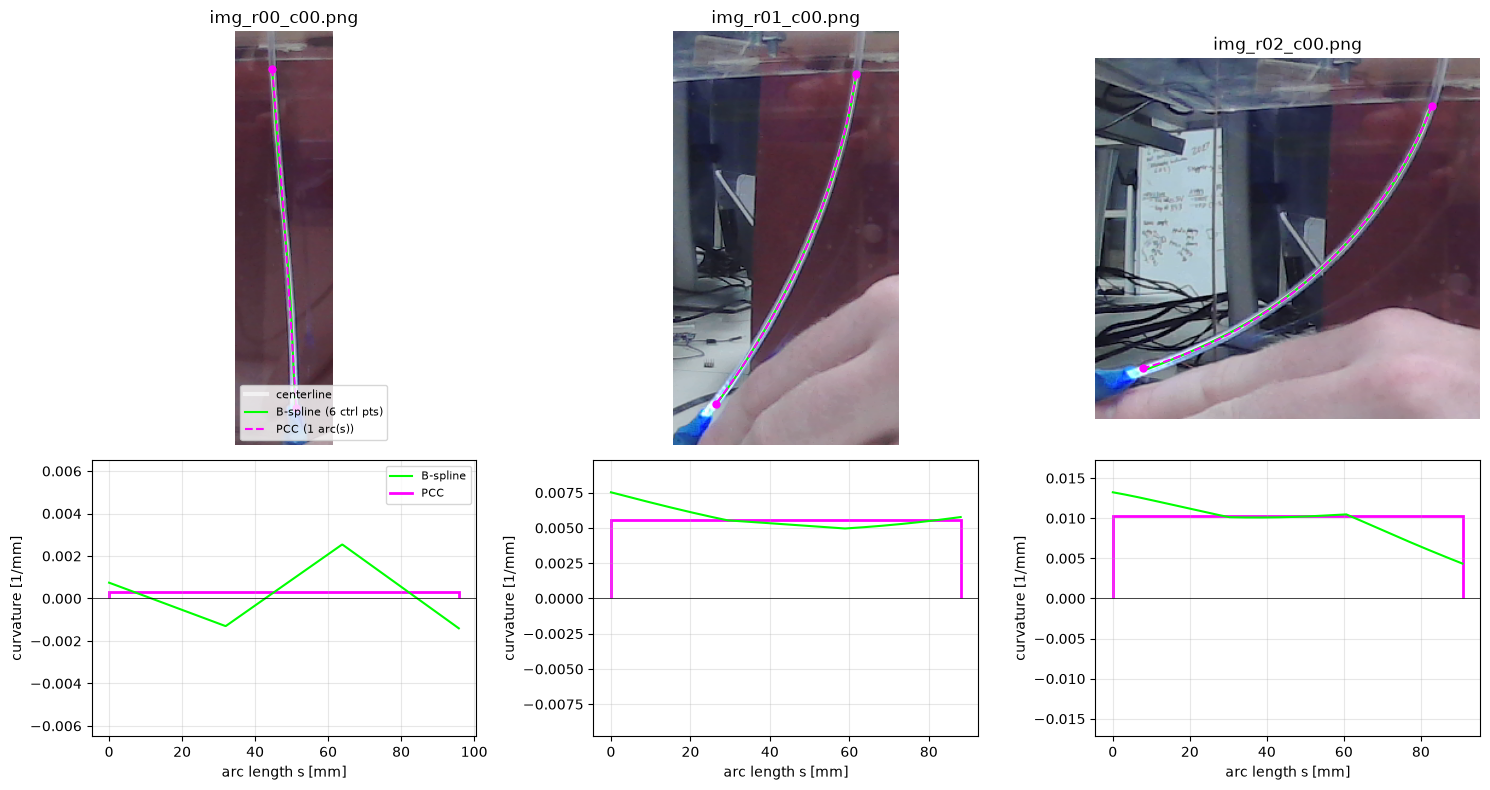

In [ ]:
# segment the fiber and encode its shape as piecewise constant curvature (PCC)
#
# Segmentation reuses sw/segment_fiber.py (clamp point from <grid_dir>/seg_config.json, so no GUI here).
# The centerline is converted to mm with the image scale from the fiber width (px/mm = width / FIBER_DIAM_MM),
# then fitted with the fewest constant-curvature arcs (up to MAX_SEGS) whose rms distance to the
# centerline is below TOL_MM. Breakpoints are initialised by dynamic programming on theta(s) (theta linear
# per arc), then heading, curvatures and breakpoints are refined jointly on the xy positions, which is far less
# sensitive to tangent noise than fitting theta directly. The fitted curve is tangent-continuous by construction.
#
# Encoding (per image): start point + initial heading theta0, then [(L_mm, kappa_per_mm), ...] from clamp to tip.
# theta is measured below horizontal in image coordinates (90 deg = straight down); kappa > 0 turns clockwise
# on screen (image y points down), same convention as segment_fiber.py.
import sys, json, importlib
import numpy as np
from scipy.optimize import least_squares

sys.path.insert(0, str(Path(r"C:\Users\alagi\shape-sensing\sw")))
import segment_fiber as sf
importlib.reload(sf)   # pick up edits to segment_fiber.py without restarting the kernel

MAX_SEGS = 5      # most arcs tried
TOL_MM = 0.5      # use the fewest arcs whose rms shape error is below this [mm]
MIN_SEG_MM = 5.0  # shortest arc allowed [mm]


def pcc_points(s, x0, y0, th0, knots, kappas):
    """Positions at arc lengths s of a chain of constant-curvature arcs (knots = arc boundaries in s)."""
    i = np.clip(np.searchsorted(knots, s, side="right") - 1, 0, len(kappas) - 1)
    L = np.diff(knots)
    th_k = th0 + np.r_[0, np.cumsum(kappas * L)]                 # heading at each knot

    def chord(th, k, t):                                          # displacement along an arc of length t
        small = np.abs(k * t) < 1e-6
        ks = np.where(small, 1.0, k)
        dx = np.where(small, t * np.cos(th), (np.sin(th + k * t) - np.sin(th)) / ks)
        dy = np.where(small, t * np.sin(th), (np.cos(th) - np.cos(th + k * t)) / ks)
        return dx, dy

    dxk, dyk = chord(th_k[:-1], kappas, L)
    xk, yk = x0 + np.r_[0, np.cumsum(dxk)], y0 + np.r_[0, np.cumsum(dyk)]
    dx, dy = chord(th_k[i], kappas[i], s - knots[i])
    return np.column_stack([xk[i] + dx, yk[i] + dy])


def dp_breaks(s, th, max_segs):
    """For each K = 1..max_segs: interior breakpoints minimising the least-squares error of theta linear in s per segment."""
    n = len(s)
    c = lambda a: np.r_[0, np.cumsum(a)]
    S1, S2, T1, T2, ST = c(s), c(s * s), c(th), c(th * th), c(s * th)
    i, j = np.triu_indices(n + 1, 2)                              # segment = samples i..j-1 (>= 2 samples)
    m = j - i
    sx, ty = S1[j] - S1[i], T1[j] - T1[i]
    vs, cov, vt = S2[j] - S2[i] - sx**2 / m, ST[j] - ST[i] - sx * ty / m, T2[j] - T2[i] - ty**2 / m
    C = np.full((n + 1, n + 1), np.inf)
    C[i, j] = np.maximum(vt - cov**2 / np.maximum(vs, 1e-12), 0)
    best = np.full((max_segs + 1, n + 1), np.inf)
    best[0, 0] = 0
    arg = np.zeros_like(best, dtype=int)
    for k in range(1, max_segs + 1):
        tot = best[k - 1][:, None] + C
        arg[k] = np.argmin(tot, 0)
        best[k] = tot[arg[k], np.arange(n + 1)]
    out = {}
    for K in range(1, max_segs + 1):
        bk, jj = [], n
        for k in range(K, 1, -1):
            jj = arg[k][jj]
            bk.append(jj)
        out[K] = np.sort(s[np.array(bk, int)])
    return out


def fit_pcc(s, xy, th, max_segs=MAX_SEGS, tol=TOL_MM, min_seg=MIN_SEG_MM):
    """Fewest arcs (<= max_segs) matching the centerline within tol. Start fixed at the first sample."""
    x0, y0, Ltot = xy[0, 0], xy[0, 1], s[-1]
    sub = np.linspace(0, len(s) - 1, 150).astype(int)             # DP init on a subsample (fast)
    inits = dp_breaks(s[sub], th[sub], max_segs)
    fits = []
    for K in range(1, max_segs + 1):
        if K * min_seg > Ltot:
            break
        b0 = np.clip(inits[K], min_seg, Ltot - min_seg)
        knots0 = np.r_[0, b0, Ltot]
        k0 = [(np.interp(b, s, th) - np.interp(a, s, th)) / (b - a) for a, b in zip(knots0[:-1], knots0[1:])]

        def model(p):
            knots = np.r_[0, np.sort(p[1 + K:]), Ltot]
            return knots, pcc_points(s, x0, y0, p[0], knots, p[1:1 + K])

        def resid(p):
            knots, pts = model(p)
            short = np.maximum(min_seg - np.diff(knots), 0)          # keep arcs from collapsing
            return np.r_[(pts - xy).ravel(), 10 * short]

        lb = np.r_[-np.inf, [-np.inf] * K, [min_seg] * (K - 1)]
        ub = np.r_[np.inf, [np.inf] * K, [Ltot - min_seg] * (K - 1)]
        sol = least_squares(resid, np.r_[th[0], k0, b0], bounds=(lb, ub), x_scale="jac")
        knots, pts = model(sol.x)
        err = np.linalg.norm(pts - xy, axis=1)
        fits.append(dict(theta0=sol.x[0], knots=knots, kappas=sol.x[1:1 + K], pts=pts,
                         rms=np.sqrt(np.mean(err**2)), max=err.max(), tip=err[-1]))
        if fits[-1]["rms"] < tol:
            return fits[-1]
    return min(fits, key=lambda f: f["rms"])                      # tolerance not reached: best effort


cfg = json.loads((grid_dir / "seg_config.json").read_text())
pcc_results = {}
for name, img in images:
    try:
        res = sf.segment(img, cfg["clamp"], cfg.get("init_dir", sf.INIT_DIR))
    except RuntimeError as e:
        print(f"{name}: segmentation FAILED ({e})\n")
        continue
    cl = res["centerline"]
    px_per_mm = res["width"] / sf.FIBER_DIAM_MM
    s, xy, th = cl[:, 0] / px_per_mm, cl[:, 2:4] / px_per_mm, np.unwrap(cl[:, 4])
    fit = fit_pcc(s, xy, th)
    L, k = np.diff(fit["knots"]), fit["kappas"]
    encoding = [(round(float(a), 2), round(float(b), 5)) for a, b in zip(L, k)]
    pcc_results[name] = dict(seg=res, px_per_mm=px_per_mm, fit=fit, encoding=encoding)

    flag = "" if fit["rms"] < TOL_MM else f"  (!) tolerance {TOL_MM} mm not reached"
    print(f"{name}: L = {s[-1]:.1f} mm, {px_per_mm:.2f} px/mm, end: {res['end']}, {len(L)} arc(s){flag}")
    print(f"  start ({xy[0, 0]:.1f}, {xy[0, 1]:.1f}) mm, theta0 = {np.degrees(fit['theta0']):.1f} deg")
    print(f"  {'#':>3} {'s0 mm':>7} {'L mm':>7} {'kappa 1/mm':>11} {'R mm':>8} {'dtheta deg':>11}")
    for i, (s0, Li, ki) in enumerate(zip(fit["knots"], L, k)):
        R = f"{1 / abs(ki):8.1f}" if abs(ki) > 1e-6 else "     inf"
        print(f"  {i:>3} {s0:7.1f} {Li:7.1f} {ki:+11.5f} {R} {np.degrees(ki * Li):+11.1f}")
    print(f"  error vs centerline: rms {fit['rms']:.2f} mm, max {fit['max']:.2f} mm, tip {fit['tip']:.2f} mm")
    print(f"  encoding [(L_mm, kappa_per_mm), ...] = {encoding}\n")


# ----------------------------------------------------------------------------- PCC vs B-spline (from the cell above)
# top: both curves over the image; bottom: curvature along the fiber. The B-spline's curvature varies smoothly,
# PCC replaces it with a step per arc.
import matplotlib.pyplot as plt

names = [n for n, _ in images if n in pcc_results and n in curves]
fig, axes = plt.subplots(2, len(names), figsize=(5 * len(names), 8), squeeze=False,
                         gridspec_kw=dict(height_ratios=[3, 2]))
for col, name in enumerate(names):
    r, spl = pcc_results[name], curves[name]
    ppm, fit = r["px_per_mm"], r["fit"]
    cl = r["seg"]["centerline"]
    img = dict(images)[name]

    # top: shapes in px
    ax = axes[0, col]
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.plot(*cl[:, 2:4].T, color="white", lw=3, alpha=0.6, label="centerline")
    ax.plot(*spl(np.linspace(0, 1, 300)).T, "lime", lw=1.5, label=f"B-spline ({N_CTRL} ctrl pts)")
    ax.plot(*(fit["pts"] * ppm).T, "--", color="magenta", lw=1.5, label=f"PCC ({len(fit['kappas'])} arc(s))")
    kn = pcc_points(fit["knots"], *fit["pts"][0], fit["theta0"], fit["knots"], fit["kappas"]) * ppm
    ax.plot(*kn.T, "o", color="magenta", ms=5)                                  # arc boundaries
    pad = 40
    ax.set_xlim(cl[:, 2].min() - pad, cl[:, 2].max() + pad)
    ax.set_ylim(cl[:, 3].max() + pad, cl[:, 3].min() - pad)
    ax.set_title(name)
    ax.axis("off")

    # bottom: curvature vs arc length [1/mm]; B-spline curvature from its derivatives (px -> mm via ppm)
    ax = axes[1, col]
    u, s_mm = cl[:, 1], cl[:, 0] / ppm
    d1, d2 = spl.derivative(1)(u), spl.derivative(2)(u)
    k_spl = (d1[:, 0] * d2[:, 1] - d1[:, 1] * d2[:, 0]) / np.linalg.norm(d1, axis=1) ** 3 * ppm
    ax.plot(s_mm, k_spl, "lime", lw=1.5, label="B-spline")
    ax.stairs(fit["kappas"], fit["knots"], color="magenta", lw=2, label="PCC")
    ax.axhline(0, color="k", lw=0.5)
    lim = 1.3 * max(np.abs(k_spl).max(), np.abs(fit["kappas"]).max(), 0.005)
    ax.set_ylim(-lim, lim)
    ax.set_xlabel("arc length s [mm]")
    ax.set_ylabel("curvature [1/mm]")
    ax.grid(alpha=0.3)
axes[0, 0].legend(loc="lower left", fontsize=8)
axes[1, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()


,image,state,pd_mean_uV,pd_std_uV,pd_n,pd_t_ms,length_mm,n_arcs,kappa_mean_per_mm,radius_mm,bend_deg,theta0_deg,pcc_encoding,pcc_rms_mm,px_per_mm,width_px,edge_frac,end_x_px,end_y_px,end_reason
0,img_r00_c00.png,unbent,7.2e+05,5958,5,"(75300, 77300)",95.8,1,0.0003048,3281,1.673,85.14,"[(95.8, 0.0003)]",0.1712,3.823,9.556,0.7983,651.7,565.3,tip
1,img_r01_c00.png,medium,6.43e+05,9122,2,"(62400, 62900)",88.01,1,0.005558,179.9,28.03,99.01,"[(88.01, 0.00556)]",0.1038,3.887,9.718,0.6567,485.4,510.8,tip
2,img_r02_c00.png,most bent,5.534e+05,1.273e+04,4,"(70300, 71800)",90.81,1,0.01022,97.86,53.17,111.2,"[(90.81, 0.01022)]",0.1462,3.691,9.227,0.69,372.6,419.1,tip


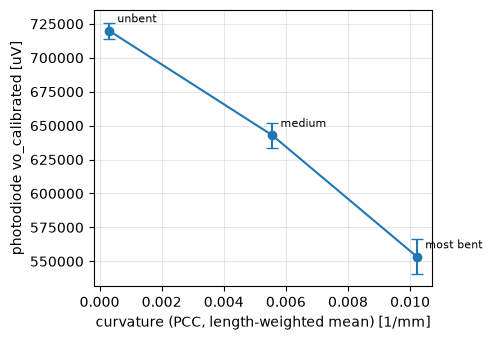

In [ ]:
# pandas data frame: photodiode reading + constant-curvature shape for each image
#
# Photodiode readings (vo_calibrated, uV) are read off the plot sensor_data/test2.png,
# so they're only good to ~+-2000 uV. Each entry is the samples inside one of the red circles:
#   circle 2 (~63 s) medium bend  -> img_r01_c00
#   circle 3 (~71 s) most bent    -> img_r02_c00
#   circle 4 (~76 s) unbent       -> img_r00_c00

import pandas as pd

photodiode = {
    "img_r00_c00.png": dict(state="unbent", t_ms=(75300, 77300), uV=[717600, 728800, 720200, 712400, 721000]),
    "img_r01_c00.png": dict(state="medium", t_ms=(62400, 62900), uV=[649400, 636500]),
    "img_r02_c00.png": dict(state="most bent", t_ms=(70300, 71800), uV=[547200, 562200, 565700, 538600]),
}

rows = []
for name, _ in images:
    pd_ = photodiode.get(name)
    r = pcc_results.get(name)
    if pd_ is None or r is None:
        print(f"{name}: skipped ({'no photodiode reading' if pd_ is None else 'no PCC fit'})")
        continue
    fit, seg = r["fit"], r["seg"]
    L = np.diff(fit["knots"])
    k = fit["kappas"]
    bend = float(np.sum(k * L))                                   # total tangent rotation [rad]
    rows.append(dict(
        image=name,
        state=pd_["state"],
        pd_mean_uV=np.mean(pd_["uV"]),
        pd_std_uV=np.std(pd_["uV"], ddof=1) if len(pd_["uV"]) > 1 else np.nan,
        pd_n=len(pd_["uV"]),
        pd_t_ms=pd_["t_ms"],
        length_mm=L.sum(),
        n_arcs=len(k),
        kappa_mean_per_mm=bend / L.sum(),                         # length-weighted mean curvature (= kappa for 1 arc)
        radius_mm=L.sum() / abs(bend) if abs(bend) > 1e-9 else np.inf,
        bend_deg=np.degrees(bend),
        theta0_deg=np.degrees(fit["theta0"]),
        pcc_encoding=r["encoding"],                               # [(L_mm, kappa_per_mm), ...] clamp -> tip
        pcc_rms_mm=fit["rms"],
        px_per_mm=r["px_per_mm"],
        width_px=seg["width"],
        edge_frac=seg["edge_frac"],
        end_x_px=seg["centerline"][-1, 2],
        end_y_px=seg["centerline"][-1, 3],
        end_reason=seg["end"],
    ))

df = pd.DataFrame(rows).sort_values("kappa_mean_per_mm").reset_index(drop=True)
with pd.option_context("display.float_format", "{:.4g}".format, "display.width", 200, "display.max_columns", None):
    display(df)

# quick look: photodiode vs curvature
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.errorbar(df["kappa_mean_per_mm"], df["pd_mean_uV"], yerr=df["pd_std_uV"], fmt="o-", capsize=4)
for _, row in df.iterrows():
    ax.annotate(row["state"], (row["kappa_mean_per_mm"], row["pd_mean_uV"]), textcoords="offset points", xytext=(6, 6), fontsize=8)
ax.set_xlabel("curvature (PCC, length-weighted mean) [1/mm]")
ax.set_ylabel("photodiode vo_calibrated [uV]")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


photodiode 600000 uV -> kappa = +0.00766 1/mm (R = 131 mm), bend = +40.2 deg, theta0 = 104.5 deg, L = 91.5 mm
  calibration: kappa = -5.932e-08 * uV + +0.0433   (calibrated range 553425 - 720000 uV)


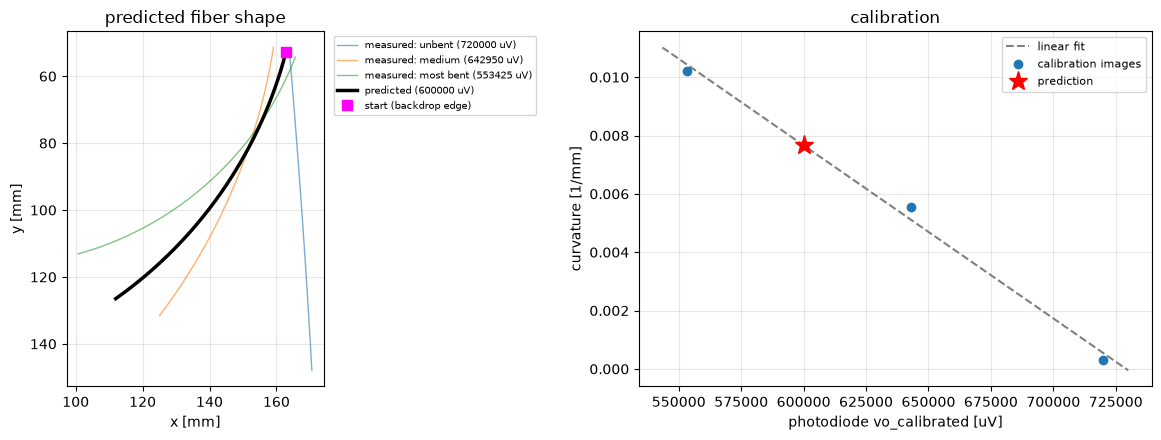

In [12]:
# predict the fiber shape from a photodiode reading
#
# Model: the fiber is one constant-curvature arc (every image above fits with 1 arc). Its curvature kappa and its
# heading where tracking starts (theta0, at the backdrop edge; the fiber already bends above it) are fitted as
# linear functions of the photodiode reading from df. Start point and length are the averages over the images.
# With only 3 calibration points this is a rough model: readings outside the calibrated range are extrapolated.
PD_UV = 600000   # <-- photodiode reading to predict [uV]

V = df["pd_mean_uV"].to_numpy()
cal_kappa = np.polyfit(V, df["kappa_mean_per_mm"], 1)
cal_theta0 = np.polyfit(V, np.radians(df["theta0_deg"]), 1)
start_mm = np.mean([pcc_results[n]["fit"]["pts"][0] for n in df["image"]], axis=0)
L_mm = df["length_mm"].mean()


def predict_shape(pd_uV, n=200):
    """Arc (x, y) [mm, image axes, y down] predicted for a photodiode reading, plus its kappa and theta0."""
    kappa, theta0 = np.polyval(cal_kappa, pd_uV), np.polyval(cal_theta0, pd_uV)
    s = np.linspace(0, L_mm, n)
    xy = pcc_points(s, *start_mm, theta0, np.array([0, L_mm]), np.array([kappa]))
    return xy, kappa, theta0


xy, kappa, theta0 = predict_shape(PD_UV)
in_range = V.min() <= PD_UV <= V.max()
print(f"photodiode {PD_UV:.0f} uV -> kappa = {kappa:+.5f} 1/mm (R = {1 / abs(kappa) if abs(kappa) > 1e-9 else np.inf:.0f} mm), "
      f"bend = {np.degrees(kappa * L_mm):+.1f} deg, theta0 = {np.degrees(theta0):.1f} deg, L = {L_mm:.1f} mm")
print(f"  calibration: kappa = {cal_kappa[0]:.3e} * uV + {cal_kappa[1]:+.4f}"
      f"   (calibrated range {V.min():.0f} - {V.max():.0f} uV)")
if not in_range:
    print("  (!) reading is outside the calibrated range: extrapolated")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw=dict(width_ratios=[1, 1.2]))
# left: predicted shape vs the measured PCC shapes, in mm, image orientation (clamp at top)
ax = axes[0]
for _, row in df.iterrows():
    pts = pcc_results[row["image"]]["fit"]["pts"]
    ax.plot(*pts.T, lw=1, alpha=0.6, label=f"measured: {row['state']} ({row['pd_mean_uV']:.0f} uV)")
ax.plot(*xy.T, "k", lw=2.5, label=f"predicted ({PD_UV:.0f} uV)")
ax.plot(*start_mm, "s", color="magenta", ms=7, label="start (backdrop edge)")
ax.set_aspect("equal")
ax.invert_yaxis()
ax.set_xlabel("x [mm]")
ax.set_ylabel("y [mm]")
ax.legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.02, 1))
ax.grid(alpha=0.3)
ax.set_title("predicted fiber shape")
# right: calibration curve with the query point
ax = axes[1]
Vg = np.linspace(min(V.min(), PD_UV) - 10000, max(V.max(), PD_UV) + 10000, 100)
ax.plot(Vg, np.polyval(cal_kappa, Vg), "--", color="0.5", label="linear fit")
ax.plot(V, df["kappa_mean_per_mm"], "o", label="calibration images")
ax.plot(PD_UV, kappa, "*", color="red", ms=14, label="prediction")
ax.set_xlabel("photodiode vo_calibrated [uV]")
ax.set_ylabel("curvature [1/mm]")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
ax.set_title("calibration")
plt.tight_layout()
plt.show()
